# Retail Sales Analysis — ShopSmart India (2024–2025)
**Tools:** Python · pandas · NumPy · Matplotlib · statistics / SciPy · Excel (openpyxl)

**Business questions**
1. How is revenue trending, and is there seasonality?
2. Which categories, regions and customers drive revenue?
3. Do discounts change buying behaviour?
4. What drives returns and low ratings?

Workflow: **load → clean → explore → test → visualise → report**

In [ ]:
import sys, statistics as st
sys.path.insert(0, '../src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from clean import clean, RAW
from analysis import (kpis, descriptive_stats, iqr_outliers, aggregates,
                      statistical_tests, correlation_matrix, key_insights)
pd.set_option('display.float_format', '{:,.2f}'.format)
pd.set_option('display.max_colwidth', 100)

## 1. Load the raw data & assess quality

In [ ]:
raw = pd.read_csv(RAW)
print(raw.shape)
raw.head()

(6090, 16)


,order_id,order_date,customer_id,customer_age,gender,city,region,category,sub_category,unit_price,quantity,discount_pct,payment_method,delivery_days,rating,returned
0,ORD100079,2024-01-14,C00160,29.00,Female,Ahmedabad,West,Electronics,Headphones,"27,290.00",1,0,Credit Card,5,4.00,No
1,ORD101612,2024-08-22,C00885,27.00,Male,Bhubaneswar,East,Electronics,Laptops,"23,380.00",1,5,Net Banking,4,4.00,No
2,ORD101718,2024-09-04,C00408,32.00,Male,Mumbai,NaN,Home & Kitchen,Decor,910.00,2,10,Cash on Delivery,1,3.00,No
3,ORD100561,2024-03-31,C00504,37.00,Male,Bengaluru,South,Sports,Cycling,"2,770.00",1,10,Cash on Delivery,3,4.00,No
4,ORD105359,2025-11-02,C01208,NaN,Female,Lucknow,North,Books,Fiction,350.00,1,0,UPI,7,NaN,No


In [ ]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 6090 entries, 0 to 6089
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        6090 non-null   str    
 1   order_date      6090 non-null   str    
 2   customer_id     6090 non-null   str    
 3   customer_age    5846 non-null   float64
 4   gender          6090 non-null   str    
 5   city            6090 non-null   str    
 6   region          6030 non-null   str    
 7   category        6090 non-null   str    
 8   sub_category    6090 non-null   str    
 9   unit_price      6090 non-null   float64
 10  quantity        6090 non-null   int64  
 11  discount_pct    6090 non-null   int64  
 12  payment_method  6001 non-null   str    
 13  delivery_days   6090 non-null   int64  
 14  rating          5719 non-null   float64
 15  returned        6090 non-null   str    
dtypes: float64(3), int64(3), str(10)
memory usage: 761.4 KB


In [ ]:
quality = pd.DataFrame({'missing': raw.isna().sum(),
                        'missing_%': raw.isna().mean() * 100,
                        'unique': raw.nunique()})
print('Duplicate rows:', raw.duplicated().sum())
quality[quality['missing'] > 0]

Duplicate rows: 90


,missing,missing_%,unique
customer_age,244,4.01,46
region,60,0.99,4
payment_method,89,1.46,6
rating,371,6.09,5


In [ ]:
# Inconsistent text values that need standardising
print(raw['category'].value_counts().head(10))
print(raw['returned'].value_counts())
print('Negative prices:', (raw['unit_price'] < 0).sum(),
      '| qty = 999:', (raw['quantity'] == 999).sum(),
      '| age > 100:', (raw['customer_age'] > 100).sum())

category
Fashion           1457
Electronics       1288
Home & Kitchen    1026
Beauty             833
Books              672
Sports             632
electronics         46
fashion             33
home & kitchen      29
beauty              28
Name: count, dtype: int64
returned
No     5200
Yes     649
Y       121
N       120
Name: count, dtype: int64
Negative prices: 18 | qty = 999: 19 | age > 100: 12


## 2. Clean the data
All rules live in `src/clean.py`; every step is logged.

In [ ]:
df, log = clean(raw)
print(f'{len(raw):,} raw rows -> {len(df):,} clean rows')
log

6,090 raw rows -> 5,982 clean rows


,step,rows_affected,detail
0,Remove duplicates,90,Dropped exact duplicate rows (same order exported twice)
1,Standardise 'city',528,"Trimmed spaces, applied Title Case"
2,Standardise 'category',180,"Trimmed spaces, applied Title Case"
3,Standardise 'gender',0,"Trimmed spaces, applied Title Case"
4,Standardise 'payment_method',120,'upi' -> 'UPI'
5,Standardise 'returned',238,'Y'/'N' -> 'Yes'/'No'
6,Parse dates,300,Converted DD/MM/YYYY rows to proper dates
7,Fix negative prices,18,Sign error - took absolute value
8,Drop placeholder quantity,18,"quantity = 999 is a system placeholder, rows removed"
9,Invalid ages,12,Age > 100 set to missing (imputed next)


In [ ]:
df[['order_date','category','region','unit_price','quantity','discount_pct','net_sales']].head()

,order_date,category,region,unit_price,quantity,discount_pct,net_sales
0,2024-01-01,Fashion,South,"2,360.00",1,0,"2,360.00"
1,2024-01-01,Books,North,240.00,3,0,720.00
2,2024-01-01,Electronics,South,"12,100.00",1,5,"11,495.00"
3,2024-01-01,Fashion,South,"2,400.00",3,30,"5,040.00"
4,2024-01-01,Home & Kitchen,North,"9,690.00",1,0,"9,690.00"


## 3. KPIs

In [ ]:
k = kpis(df)
pd.Series(k).to_frame('value')

,value
Total revenue (INR),"54,647,553.50"
Total orders,"5,982.00"
Unique customers,"2,061.00"
Units sold,"11,721.00"
Average order value (INR),"9,135.33"
Total discount given (INR),"6,815,016.50"
Return rate (%),12.60
Average rating (1-5),3.83
Revenue 2024 (INR),"25,653,547.50"
Revenue 2025 (INR),"28,994,006.00"


## 4. Descriptive statistics
Using Python's built-in `statistics` module plus NumPy percentiles.

In [ ]:
descriptive_stats(df)

,metric,count,mean,median,mode,std_dev,variance,min,Q1,Q3,max,IQR,skewness
0,net_sales,5982,"9,135.33","2,560.00",720.00,"20,023.22","400,929,268.62",120.00,"1,007.00","7,357.50","253,215.00","6,350.50",4.99
1,unit_price,5982,"5,227.32","1,680.00",420.00,"9,933.68","98,677,946.44",150.00,650.00,"4,330.00","64,900.00","3,680.00",3.44
2,quantity,5982,1.96,2.00,1.00,1.05,1.11,1.00,1.00,3.00,8.00,2.00,1.20
3,customer_age,5982,32.14,32.00,32.00,8.37,70.05,18.00,26.00,38.00,68.00,12.00,0.28
4,delivery_days,5982,4.18,4.00,4.00,1.63,2.67,1.00,3.00,5.00,11.00,2.00,0.16
5,rating,5624,3.83,4.00,4.00,0.79,0.62,1.00,3.00,4.00,5.00,1.00,-0.22


In [ ]:
# Quick demo of the statistics module on order value
x = df['net_sales'].tolist()
print(f'mean   = {st.mean(x):,.0f}')
print(f'median = {st.median(x):,.0f}')
print(f'stdev  = {st.stdev(x):,.0f}')
print(f'deciles= {[round(q) for q in st.quantiles(x, n=10)]}')

mean   = 9,135
median = 2,560
stdev  = 20,023
deciles= [504, 819, 1224, 1765, 2560, 3739, 5797, 9713, 22209]


Order value is **heavily right-skewed** (skew ≈ 5): the mean is ~3.5× the median, so the median is the better 'typical order'.

In [ ]:
iqr_outliers(df).T

,0
column,net_sales
Q1,"1,007.00"
Q3,"7,357.50"
upper_fence,"16,883.25"
outlier_orders,768
share_of_orders_%,12.84
share_of_revenue_%,67.23
decision,"Kept - genuine high-value orders (mostly Electronics), not errors"


## 5. Exploratory analysis (pandas groupby / pivot)

In [ ]:
a = aggregates(df)
a['category']

,category,revenue,orders,units,avg_order_value,return_rate,avg_rating,revenue_share_%
0,Electronics,"37,947,840.00",1311,2548,"28,945.72",0.18,3.84,69.44
1,Home & Kitchen,"5,665,420.50",1030,2020,"5,500.41",0.09,3.80,10.37
2,Fashion,"4,521,983.00",1469,2890,"3,078.27",0.21,3.84,8.27
3,Sports,"4,385,228.50",645,1291,"6,798.80",0.06,3.85,8.02
4,Beauty,"1,553,896.50",846,1669,"1,836.76",0.06,3.82,2.84
5,Books,"573,185.00",681,1303,841.68,0.05,3.83,1.05


In [ ]:
a['region']

,region,revenue,orders,units,avg_order_value,return_rate,avg_rating
0,South,"16,760,504.50",1759,3460,"9,528.43",0.13,3.85
1,North,"14,868,748.50",1626,3194,"9,144.37",0.13,3.86
2,West,"14,358,986.50",1454,2830,"9,875.51",0.11,3.86
3,East,"8,659,314.00",1143,2237,"7,575.95",0.13,3.71


In [ ]:
a['pivot_region_cat'].style.format('{:,.0f}').background_gradient(cmap='Blues', axis=None)

category,Beauty,Books,Electronics,Fashion,Home & Kitchen,Sports,Total
region,,,,,,,
East,"309,132","115,107","5,468,720","906,290","1,064,351","795,714","8,659,314"
North,"423,336","143,014","10,513,927","1,251,554","1,261,874","1,275,042","14,868,748"
South,"463,700","172,230","11,405,011","1,281,342","2,043,946","1,394,275","16,760,504"
West,"357,729","142,833","10,560,182","1,082,796","1,295,249","920,196","14,358,986"
Total,"1,553,896","573,185","37,947,840","4,521,983","5,665,420","4,385,228","54,647,554"


In [ ]:
a['seasonality'].style.format('{:,.0f}')

year,2024,2025
month_name,,
Jan,"1,620,446","1,731,751"
Feb,"1,872,278","1,659,208"
Mar,"1,569,324","2,017,962"
Apr,"2,269,517","1,971,169"
May,"2,162,467","3,000,477"
Jun,"1,817,984","1,860,894"
Jul,"1,793,594","1,470,110"
Aug,"2,114,574","2,943,441"
Sep,"1,940,328","2,382,592"


In [ ]:
a['segments']

,segment,customers,avg_orders,avg_lifetime_value,total_revenue,revenue_share_%
0,Low,516,1.66,"2,258.05","1,165,151.50",2.13
1,Medium,515,2.70,"8,359.73","4,305,262.50",7.88
2,High,516,3.43,"20,879.89","10,774,024.00",19.72
3,Premium,514,3.83,"74,714.23","38,403,115.50",70.27


## 6. Hypothesis testing (α = 0.05)

In [ ]:
tests = statistical_tests(df, a['monthly'])
tests[['test','question','statistic','p_value','result','interpretation']]

,test,question,statistic,p_value,result,interpretation
0,Welch two-sample t-test,Do discounted orders have more units than full-price orders?,22.90,0.00,Significant,Discounted orders average 2.13 units vs 1.57 at full price (+36%).
1,One-way ANOVA (log sales) / Kruskal-Wallis,Does average order value differ between regions?,1.96,0.12,Not significant,Kruskal-Wallis (non-parametric check) p = 0.272. Regions spend similarly per order; revenue gaps...
2,Chi-square test of independence,Are returns associated with product category?,222.42,0.00,Significant,Highest return rate: Fashion (20.6%); lowest: Books (5.3%). dof = 5.
3,Pearson & Spearman correlation,Do slower deliveries get lower ratings?,-0.34,0.00,Significant,"Pearson r = -0.34, Spearman rho = -0.34: moderate negative relationship."
4,Linear regression (monthly revenue trend),Is revenue trending upward over time?,0.23,0.02,Significant,"Trend adds ~INR 46,659 revenue per month (R² = 0.23; seasonality explains much of the rest)."
5,95% confidence interval (t-distribution),What is the true average order value?,"9,135.33",NaN,Estimate,"Average order value is INR 9,135; 95% CI INR 8,628 – 9,643."
6,Mann-Whitney U test,Is order value different in festive months (Oct-Nov)?,"3,278,452.50",0.27,Not significant,"Median order: festive INR 2,702 vs rest INR 2,508. Festive revenue spike is driven by more order..."


In [ ]:
correlation_matrix(df)

,net_sales,unit_price,quantity,discount_pct,delivery_days,rating,customer_age,is_returned
net_sales,1.00,0.86,0.24,0.05,-0.03,-0.00,0.01,0.06
unit_price,0.86,1.00,0.00,-0.00,-0.02,0.01,0.00,0.07
quantity,0.24,0.00,1.00,0.35,-0.02,0.01,0.00,-0.02
discount_pct,0.05,-0.00,0.35,1.00,-0.01,0.00,0.02,-0.02
delivery_days,-0.03,-0.02,-0.02,-0.01,1.00,-0.34,-0.01,-0.01
rating,-0.00,0.01,0.01,0.00,-0.34,1.00,0.00,0.00
customer_age,0.01,0.00,0.00,0.02,-0.01,0.00,1.00,0.02
is_returned,0.06,0.07,-0.02,-0.02,-0.01,0.00,0.02,1.00


## 7. Visualisations (Matplotlib)
Charts are produced by `src/visualize.py` and saved to `outputs/charts/`.

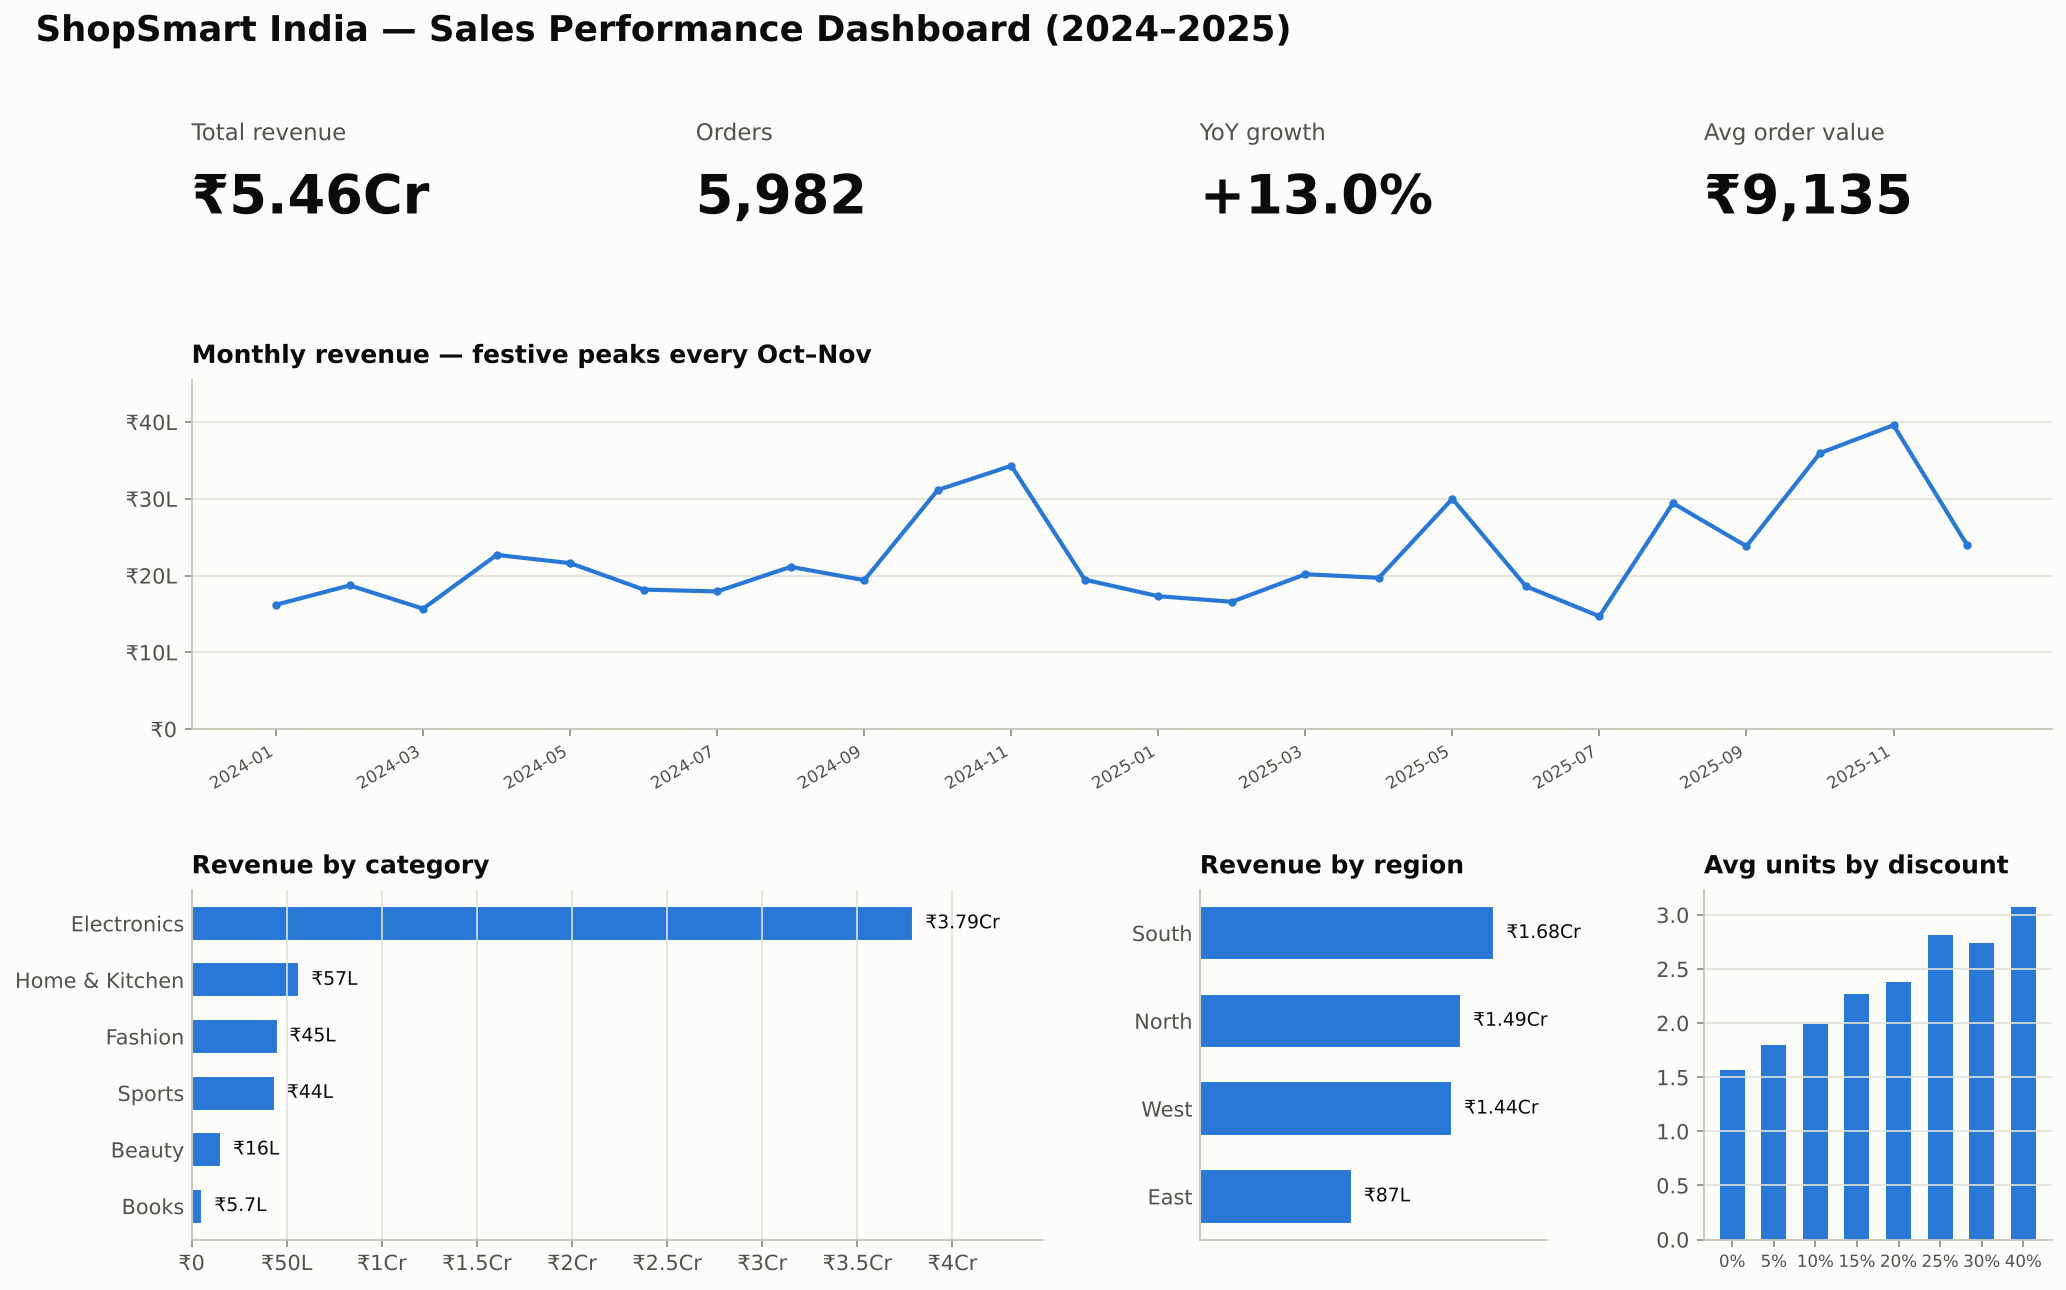

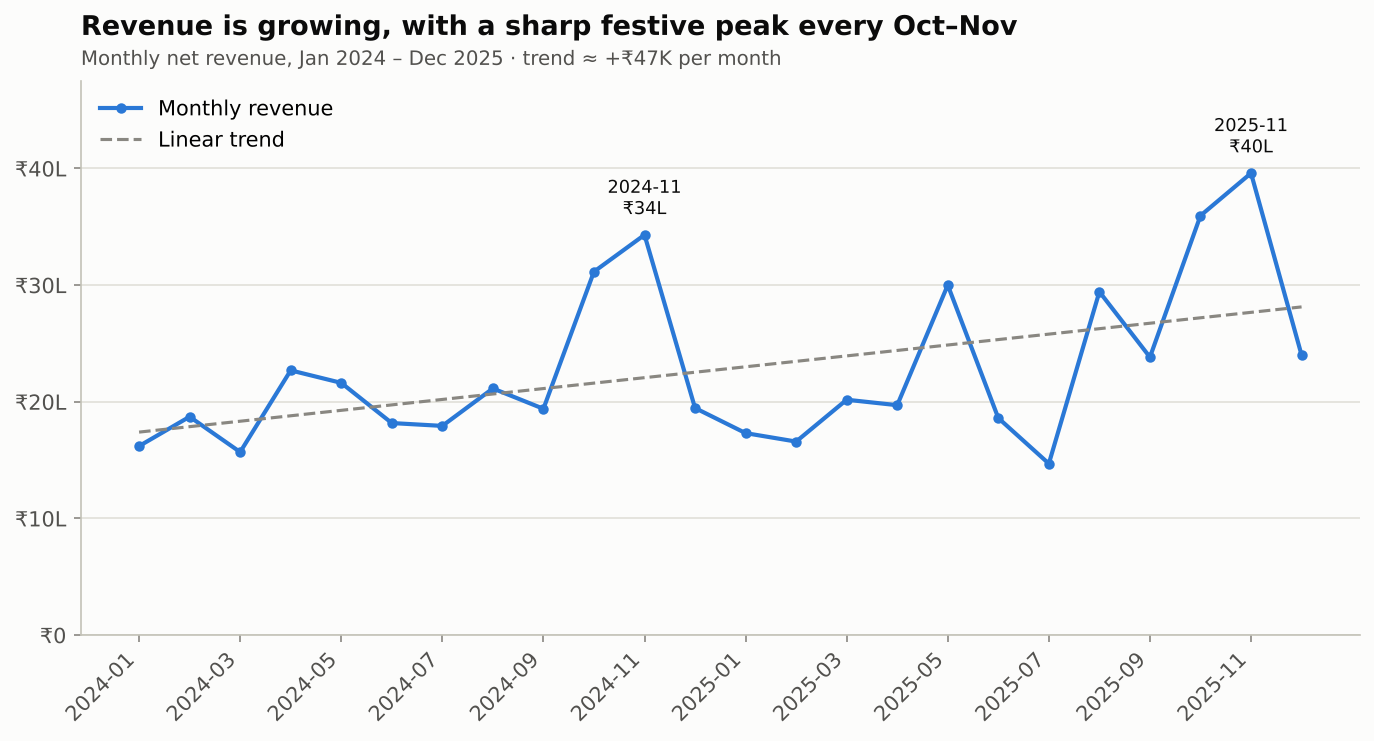

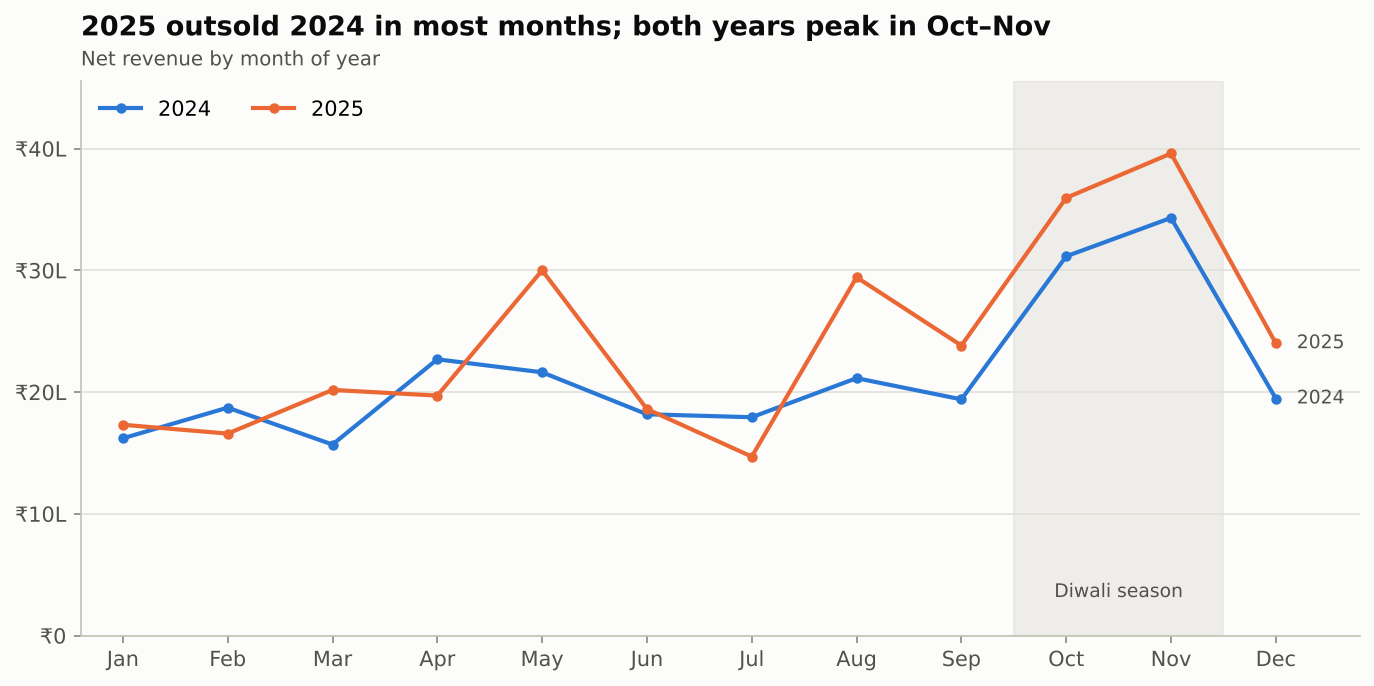

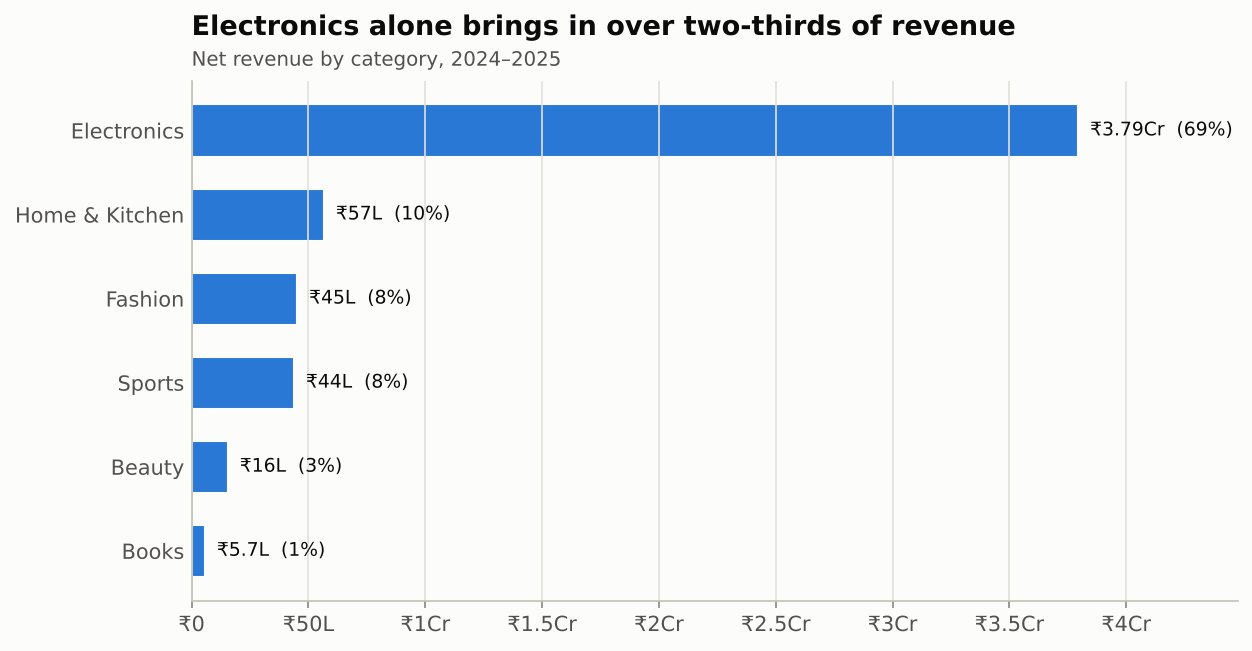

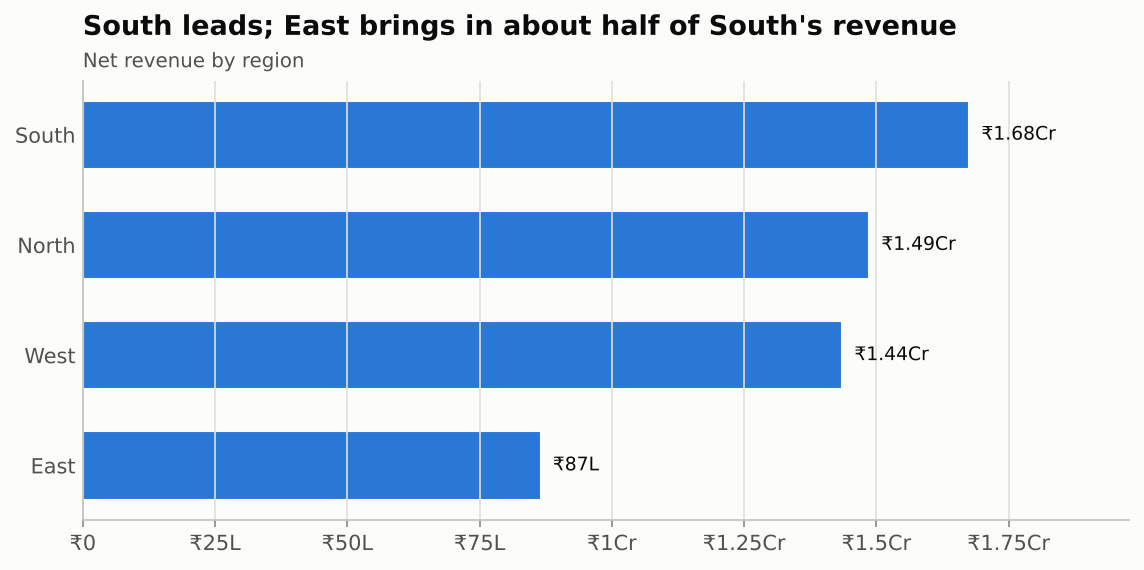

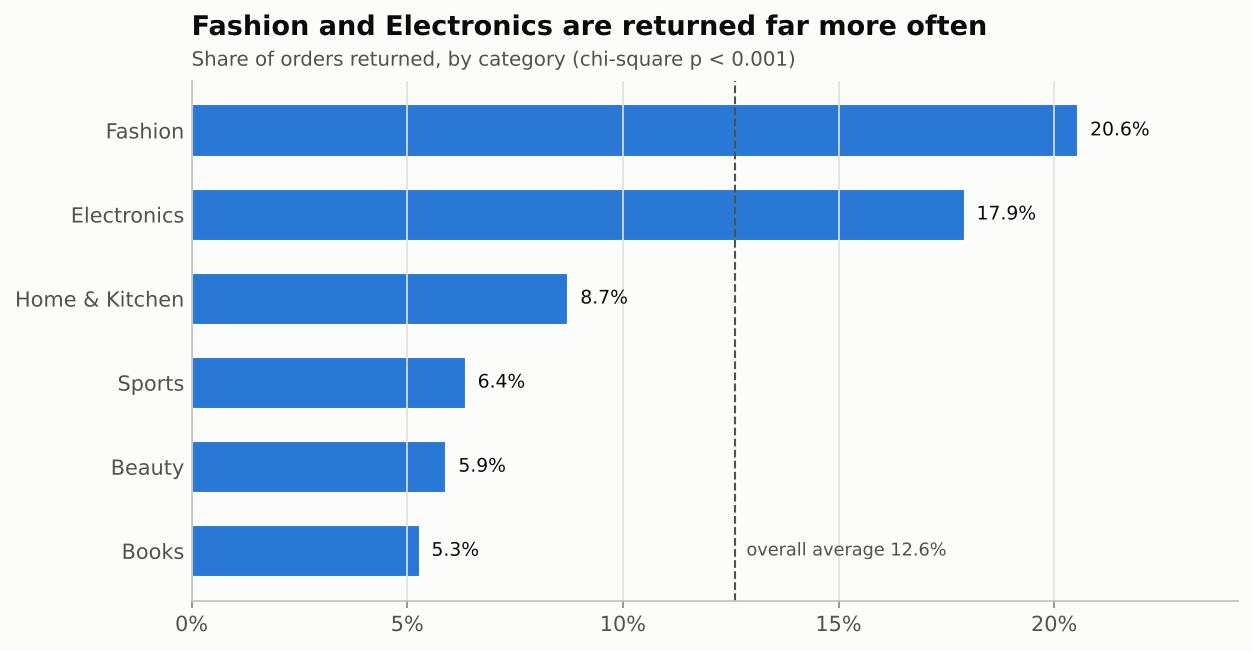

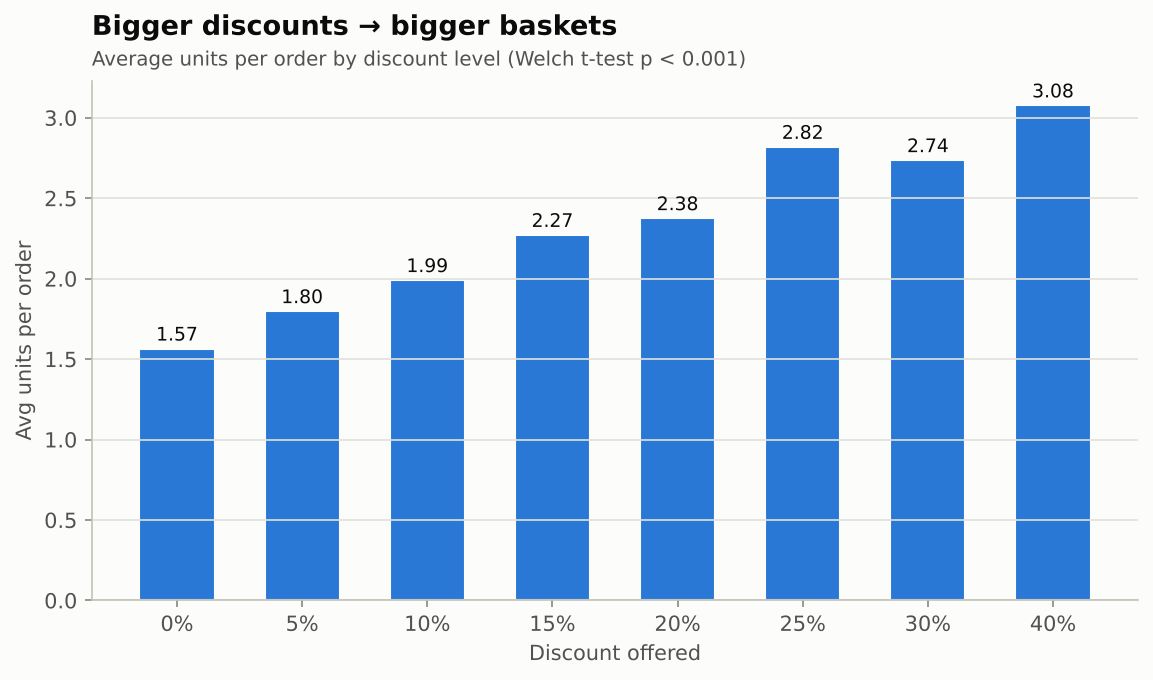

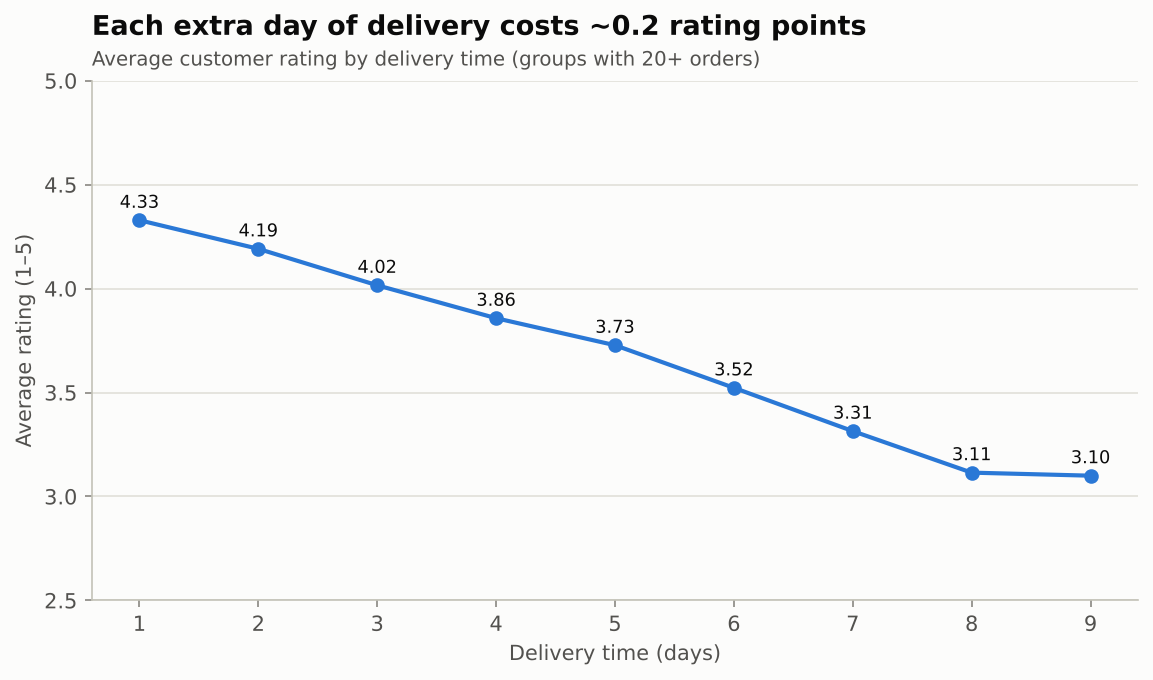

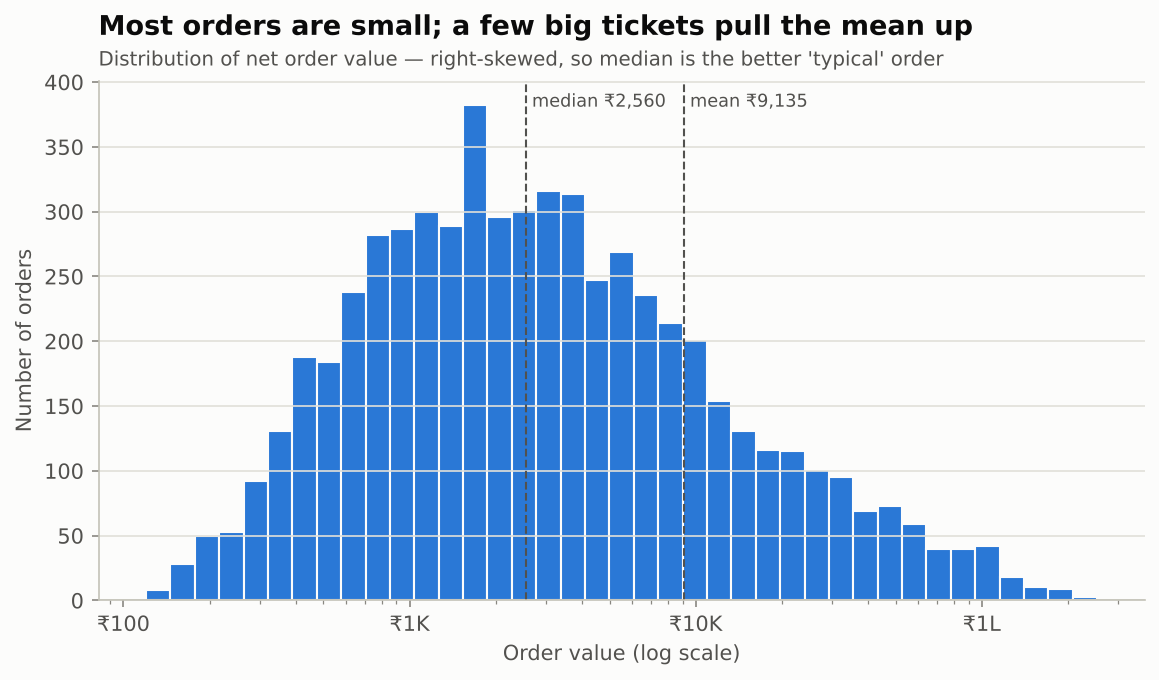

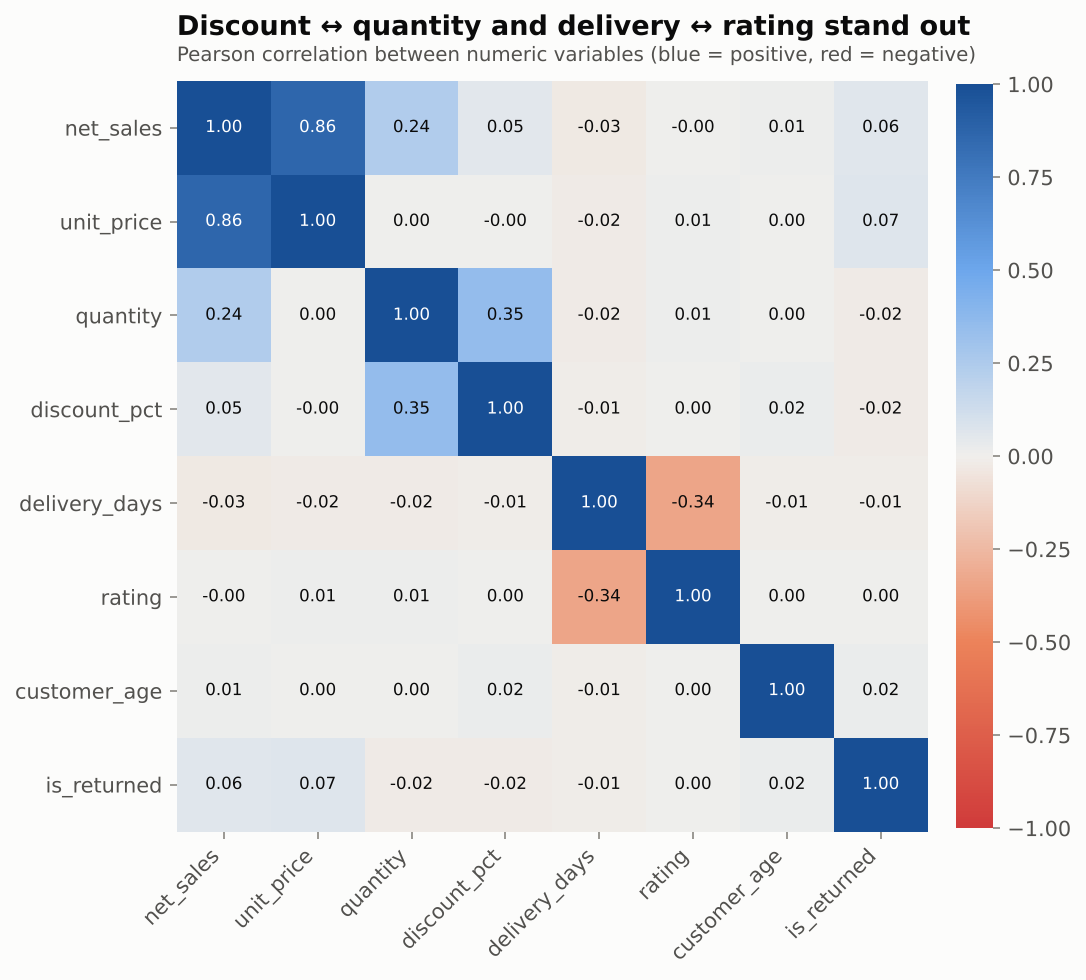

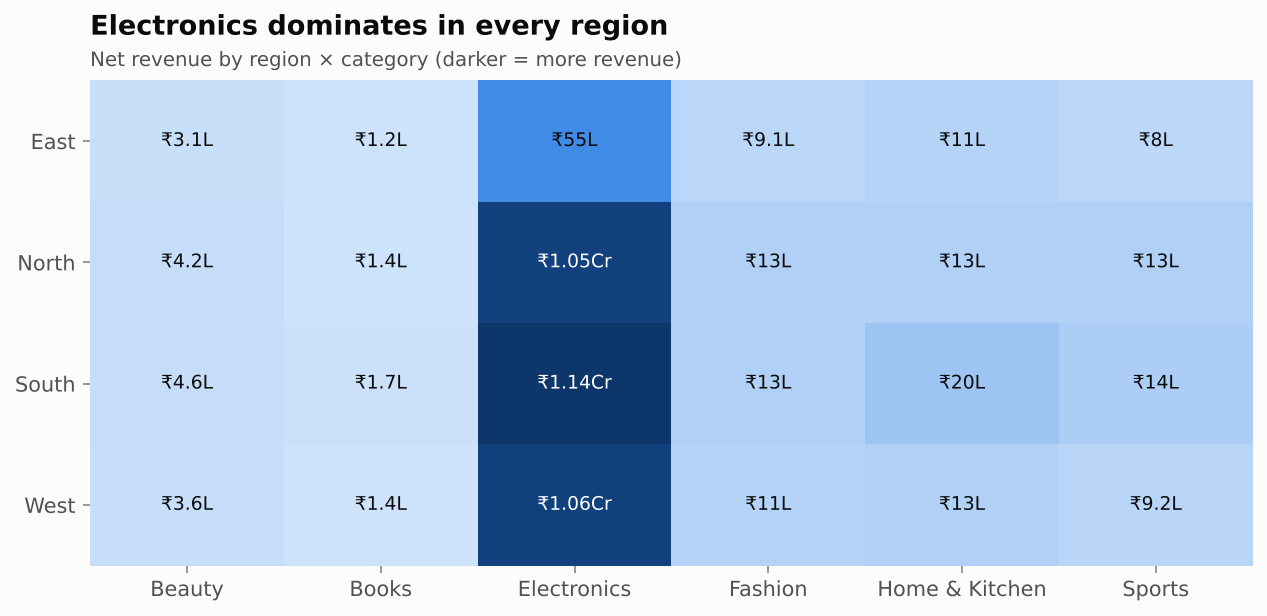

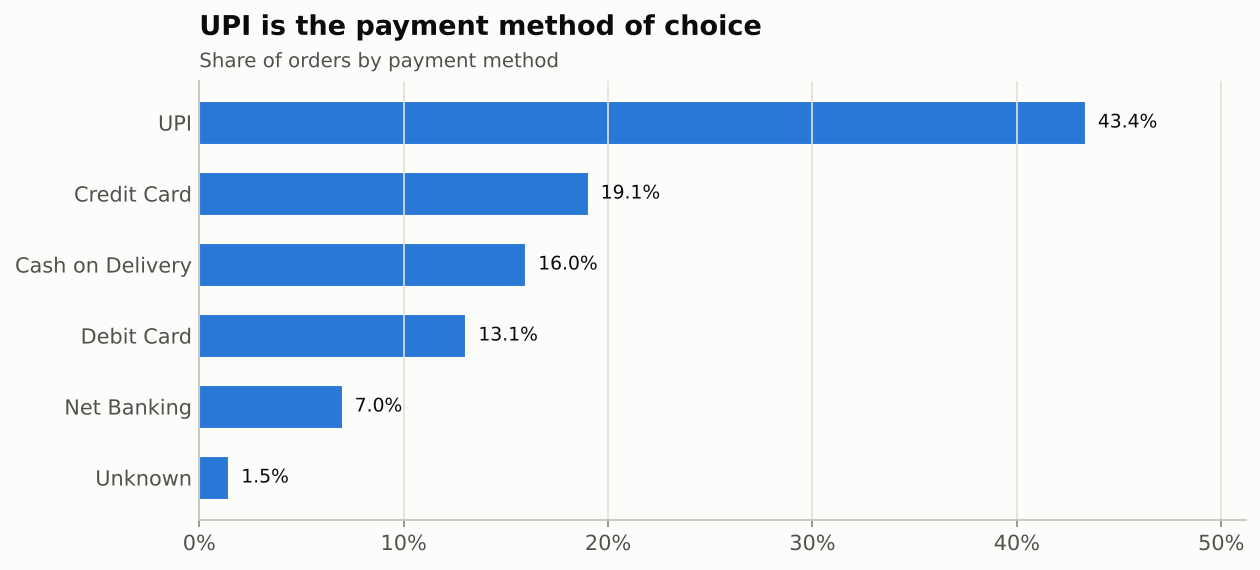

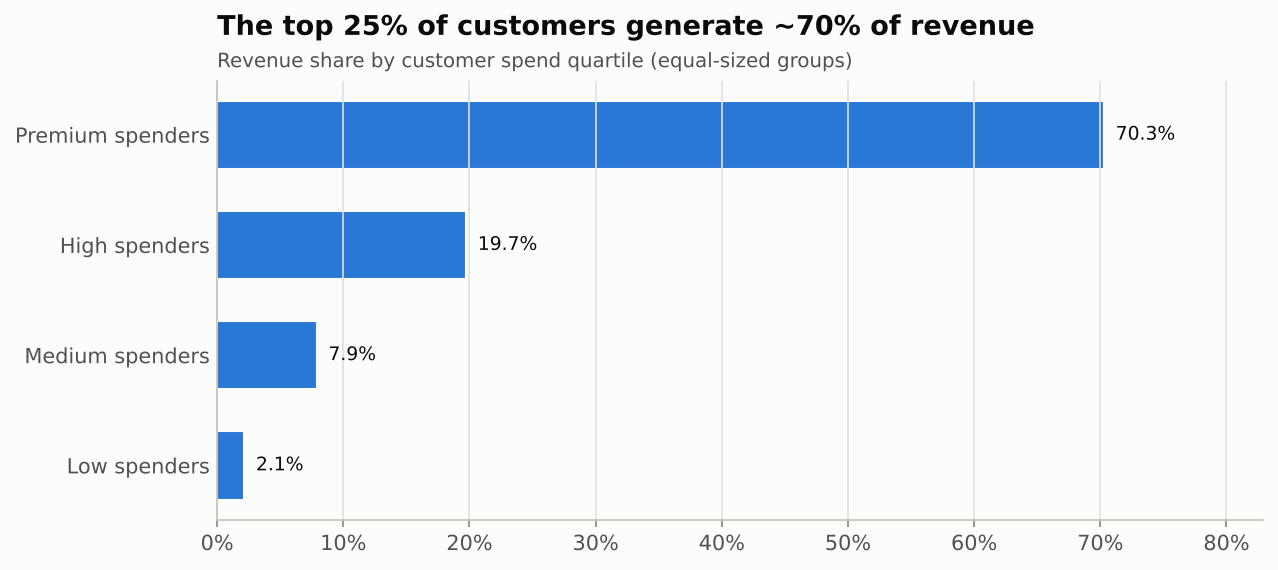

In [ ]:
from visualize import make_all
charts = make_all(df, k, a, correlation_matrix(df))
for p in charts:
    display(Image(filename=str(p), width=850))

## 8. Key insights

In [ ]:
for i, s in enumerate(key_insights(k, a, tests), 1):
    print(f'{i}. {s}')

1. Revenue grew 13.0% year-on-year (₹2.57 Cr in 2024 → ₹2.90 Cr in 2025).
2. Electronics drives 69% of revenue from only 22% of orders — it is the business's main lever.
3. October–November (Diwali season) average 1.7x the revenue of other months; the lift comes from more orders, not bigger baskets (Mann-Whitney p > 0.05).
4. South is the top region (₹1.68 Cr); East is the smallest (₹0.87 Cr) and also has the slowest deliveries.
5. UPI is the most used payment method (43% of orders).
6. Discounts lift basket size: 30%+ discount orders average 2.9 units vs 1.6 at full price (t-test p < 0.001).
7. Slower delivery hurts ratings: average rating falls from 4.33 (1-day) to 3.10 (9-day); Pearson r = -0.34.
8. Returns depend on category (chi-square p < 0.001): Fashion 20.6% and Electronics 17.9% vs Books 5.3%.
9. Premium customers (top 25% by spend) generate 70% of revenue — retention matters.


## 9. Recommendations
- **Protect Electronics** (≈69% of revenue): stock depth and pricing before Oct–Nov.
- **Plan for Diwali**: festive months bring ~1.7× revenue from *more orders* — scale logistics and customer support, not just discounts.
- **Fix East-region delivery**: slowest deliveries and lowest ratings; every extra day costs ~0.2 rating points.
- **Reduce Fashion returns** (~21%): better size guides and product photos.
- **Use discounts deliberately**: they raise units per order, so target bundles/multi-buy.
- **Retain Premium customers**: top 25% bring ~70% of revenue — loyalty programme.

The full formatted workbook is at `outputs/reports/Sales_Analysis_Report.xlsx`.